# 02 — Comparando Algoritmos de Clusterização

Teoria: [README.md](README.md) e arquivos `01_*.md` a `07_*.md` desta pasta.

**Roteiro**
1. K-Means passo a passo (algoritmo de Lloyd)
2. Escolhendo *k*: cotovelo e silhueta
3. Hierárquico: dendrograma e ligações
4. DBSCAN: gráfico k-distância
5. GMM: BIC e atribuição suave
6. Todos os algoritmos × seis tipos de dados
7. O efeito da padronização na clusterização
8. Exercícios

In [1]:
import sys
sys.path.append("..")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn import datasets
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, AgglomerativeClustering, DBSCAN, HDBSCAN
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, adjusted_rand_score,
                             calinski_harabasz_score, davies_bouldin_score)

from utils.graficos import dispersao_clusters, curva_escolha_k, cores

plt.rcParams["figure.dpi"] = 90
SEMENTE = 42

## 1. K-Means passo a passo

Implementação "na mão" do algoritmo de Lloyd para ver os centróides se movendo.
Começamos com uma inicialização **ruim** de propósito.

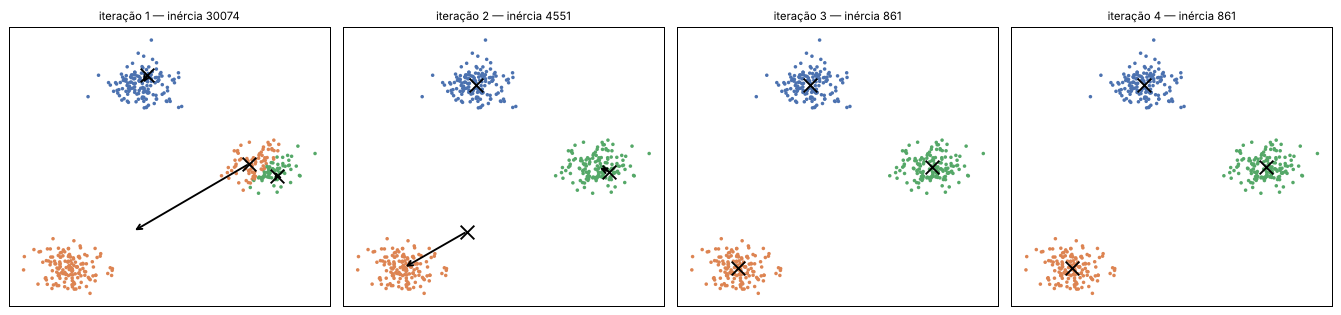

In [2]:
X, y = datasets.make_blobs(n_samples=450, centers=3, cluster_std=1.0, random_state=SEMENTE)

def passo_lloyd(X, centroides):
    dist = np.linalg.norm(X[:, None, :] - centroides[None, :, :], axis=2)  # n × k
    rotulos = dist.argmin(axis=1)                                         # atribuição
    novos = np.array([X[rotulos == c].mean(axis=0) for c in range(len(centroides))])  # atualização
    inercia = (dist[np.arange(len(X)), rotulos] ** 2).sum()
    return rotulos, novos, inercia

centroides = X[:3].copy()  # três primeiros pontos como centróides iniciais
fig, axs = plt.subplots(1, 4, figsize=(15, 3.6))
for i, ax in enumerate(axs):
    rotulos, novos, inercia = passo_lloyd(X, centroides)
    dispersao_clusters(ax, X, rotulos, f"iteração {i + 1} — inércia {inercia:.0f}")
    ax.scatter(*centroides.T, marker="x", s=120, c="k")
    for a, b in zip(centroides, novos):
        ax.annotate("", xy=b, xytext=a, arrowprops=dict(arrowstyle="->", lw=1.5))
    centroides = novos
plt.tight_layout()

A inércia cai a cada iteração (nunca sobe) e os centróides (×) convergem para o centro dos grupos.

## 2. Escolhendo *k*: cotovelo e silhueta

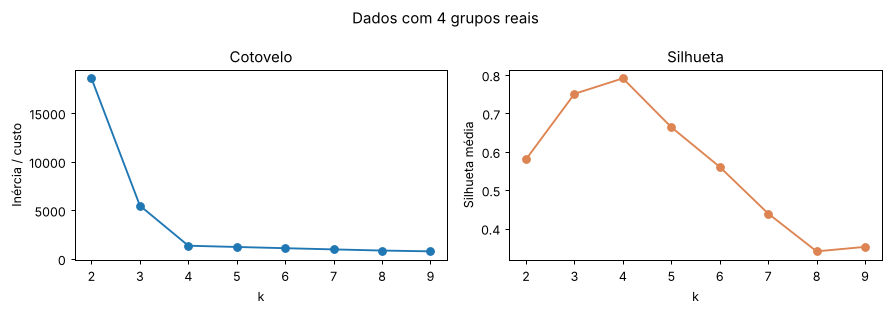

In [3]:
X4, y4 = datasets.make_blobs(n_samples=600, centers=4, cluster_std=1.1, random_state=7)
ks = range(2, 10)
inercias, silhuetas = [], []
for k in ks:
    km = KMeans(k, n_init=10, random_state=SEMENTE).fit(X4)
    inercias.append(km.inertia_)
    silhuetas.append(silhouette_score(X4, km.labels_))
curva_escolha_k(list(ks), inercias, silhuetas, "Dados com 4 grupos reais");

In [4]:
# Outras métricas internas para os mesmos k
tab = []
for k in ks:
    rot = KMeans(k, n_init=10, random_state=SEMENTE).fit_predict(X4)
    tab.append({"k": k, "silhueta ↑": silhouette_score(X4, rot),
                "Calinski-Harabasz ↑": calinski_harabasz_score(X4, rot),
                "Davies-Bouldin ↓": davies_bouldin_score(X4, rot)})
pd.DataFrame(tab).set_index("k").round(3).style.highlight_max(subset=["silhueta ↑", "Calinski-Harabasz ↑"]).highlight_min(subset=["Davies-Bouldin ↓"])

,silhueta ↑,Calinski-Harabasz ↑,Davies-Bouldin ↓
k,,,
2,0.580000,841.477000,0.798000
3,0.751000,2135.483000,0.354000
4,0.792000,6316.832000,0.296000
5,0.664000,5244.559000,0.623000
6,0.561000,4677.253000,0.829000
7,0.439000,4391.749000,0.993000
8,0.341000,4281.962000,1.131000
9,0.352000,4140.991000,1.039000


## 3. Hierárquico: dendrograma e ligações

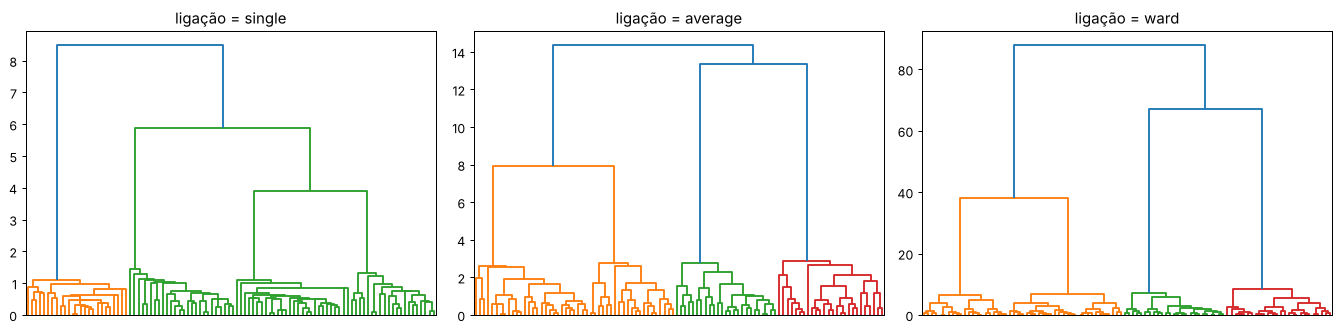

In [5]:
from scipy.cluster.hierarchy import linkage, dendrogram

amostra = X4[::6]  # 100 pontos para o dendrograma ficar legível
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for ax, metodo in zip(axs, ["single", "average", "ward"]):
    dendrogram(linkage(amostra, method=metodo), ax=ax, no_labels=True, color_threshold=None)
    ax.set_title(f"ligação = {metodo}")
plt.tight_layout()

No **Ward** os 4 grupos aparecem como saltos grandes de altura — cortar ali dá *k* = 4.
No **single** as fusões são "em escada" (efeito de encadeamento), mais difícil de cortar.

## 4. DBSCAN: escolhendo `eps` pelo gráfico k-distância

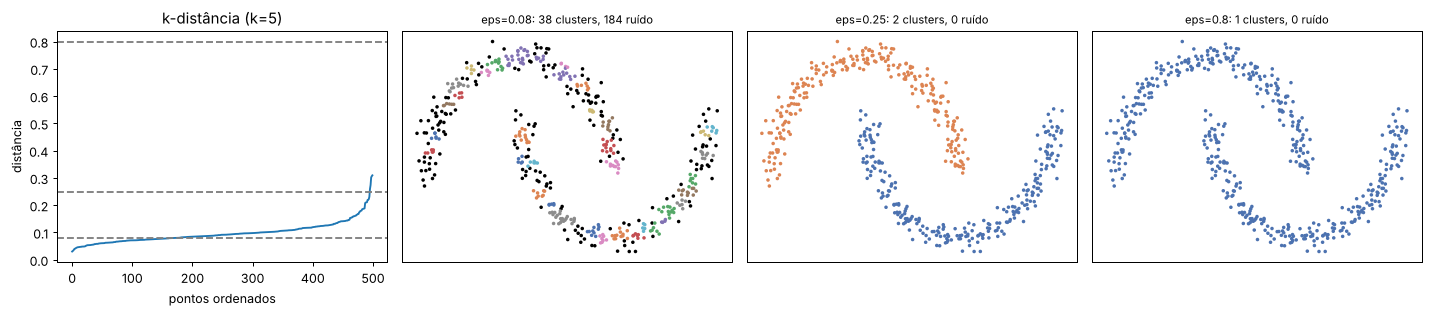

In [6]:
from sklearn.neighbors import NearestNeighbors

Xl, yl = datasets.make_moons(n_samples=500, noise=0.06, random_state=SEMENTE)
Xl = StandardScaler().fit_transform(Xl)
min_samples = 5
dist, _ = NearestNeighbors(n_neighbors=min_samples).fit(Xl).kneighbors(Xl)
kdist = np.sort(dist[:, -1])

fig, axs = plt.subplots(1, 4, figsize=(16, 3.6))
axs[0].plot(kdist); axs[0].set(title=f"k-distância (k={min_samples})", xlabel="pontos ordenados", ylabel="distância")
for ax, eps in zip(axs[1:], [0.08, 0.25, 0.8]):
    axs[0].axhline(eps, ls="--", c="gray")
    rot = DBSCAN(eps=eps, min_samples=min_samples).fit_predict(Xl)
    dispersao_clusters(ax, Xl, rot, f"eps={eps}: {len(set(rot) - {-1})} clusters, {np.sum(rot == -1)} ruído")
plt.tight_layout()

- `eps` pequeno demais → quase tudo é ruído (preto).
- `eps` perto do "joelho" → as duas luas.
- `eps` grande demais → tudo vira um cluster só.

## 5. GMM: BIC e atribuição suave

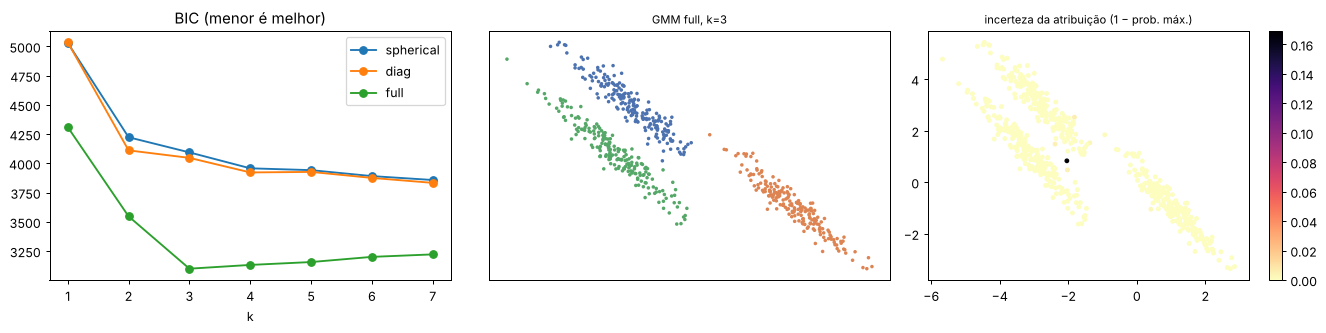

In [7]:
Xa, ya = datasets.make_blobs(n_samples=600, centers=3, random_state=170)
Xa = Xa @ np.array([[0.6, -0.64], [-0.41, 0.85]])  # deixa os grupos alongados (anisotrópicos)

bic = {tipo: [GaussianMixture(k, covariance_type=tipo, random_state=0).fit(Xa).bic(Xa) for k in range(1, 8)]
       for tipo in ["spherical", "diag", "full"]}
fig, axs = plt.subplots(1, 3, figsize=(15, 3.8))
for tipo, v in bic.items():
    axs[0].plot(range(1, 8), v, "o-", label=tipo)
axs[0].set(title="BIC (menor é melhor)", xlabel="k"); axs[0].legend()

gmm = GaussianMixture(3, covariance_type="full", random_state=0).fit(Xa)
dispersao_clusters(axs[1], Xa, gmm.predict(Xa), "GMM full, k=3")
incerteza = 1 - gmm.predict_proba(Xa).max(axis=1)
sc = axs[2].scatter(Xa[:, 0], Xa[:, 1], c=incerteza, cmap="magma_r", s=8)
axs[2].set_title("incerteza da atribuição (1 − prob. máx.)", fontsize=9); plt.colorbar(sc, ax=axs[2])
plt.tight_layout()

A incerteza é alta só na fronteira entre grupos — informação que K-Means não fornece.

## 6. Todos os algoritmos × seis tipos de dados

Inspirado no exemplo clássico do scikit-learn. O título de cada painel mostra o **ARI**
em relação aos grupos verdadeiros (exceto no conjunto sem estrutura, onde não há grupos reais).

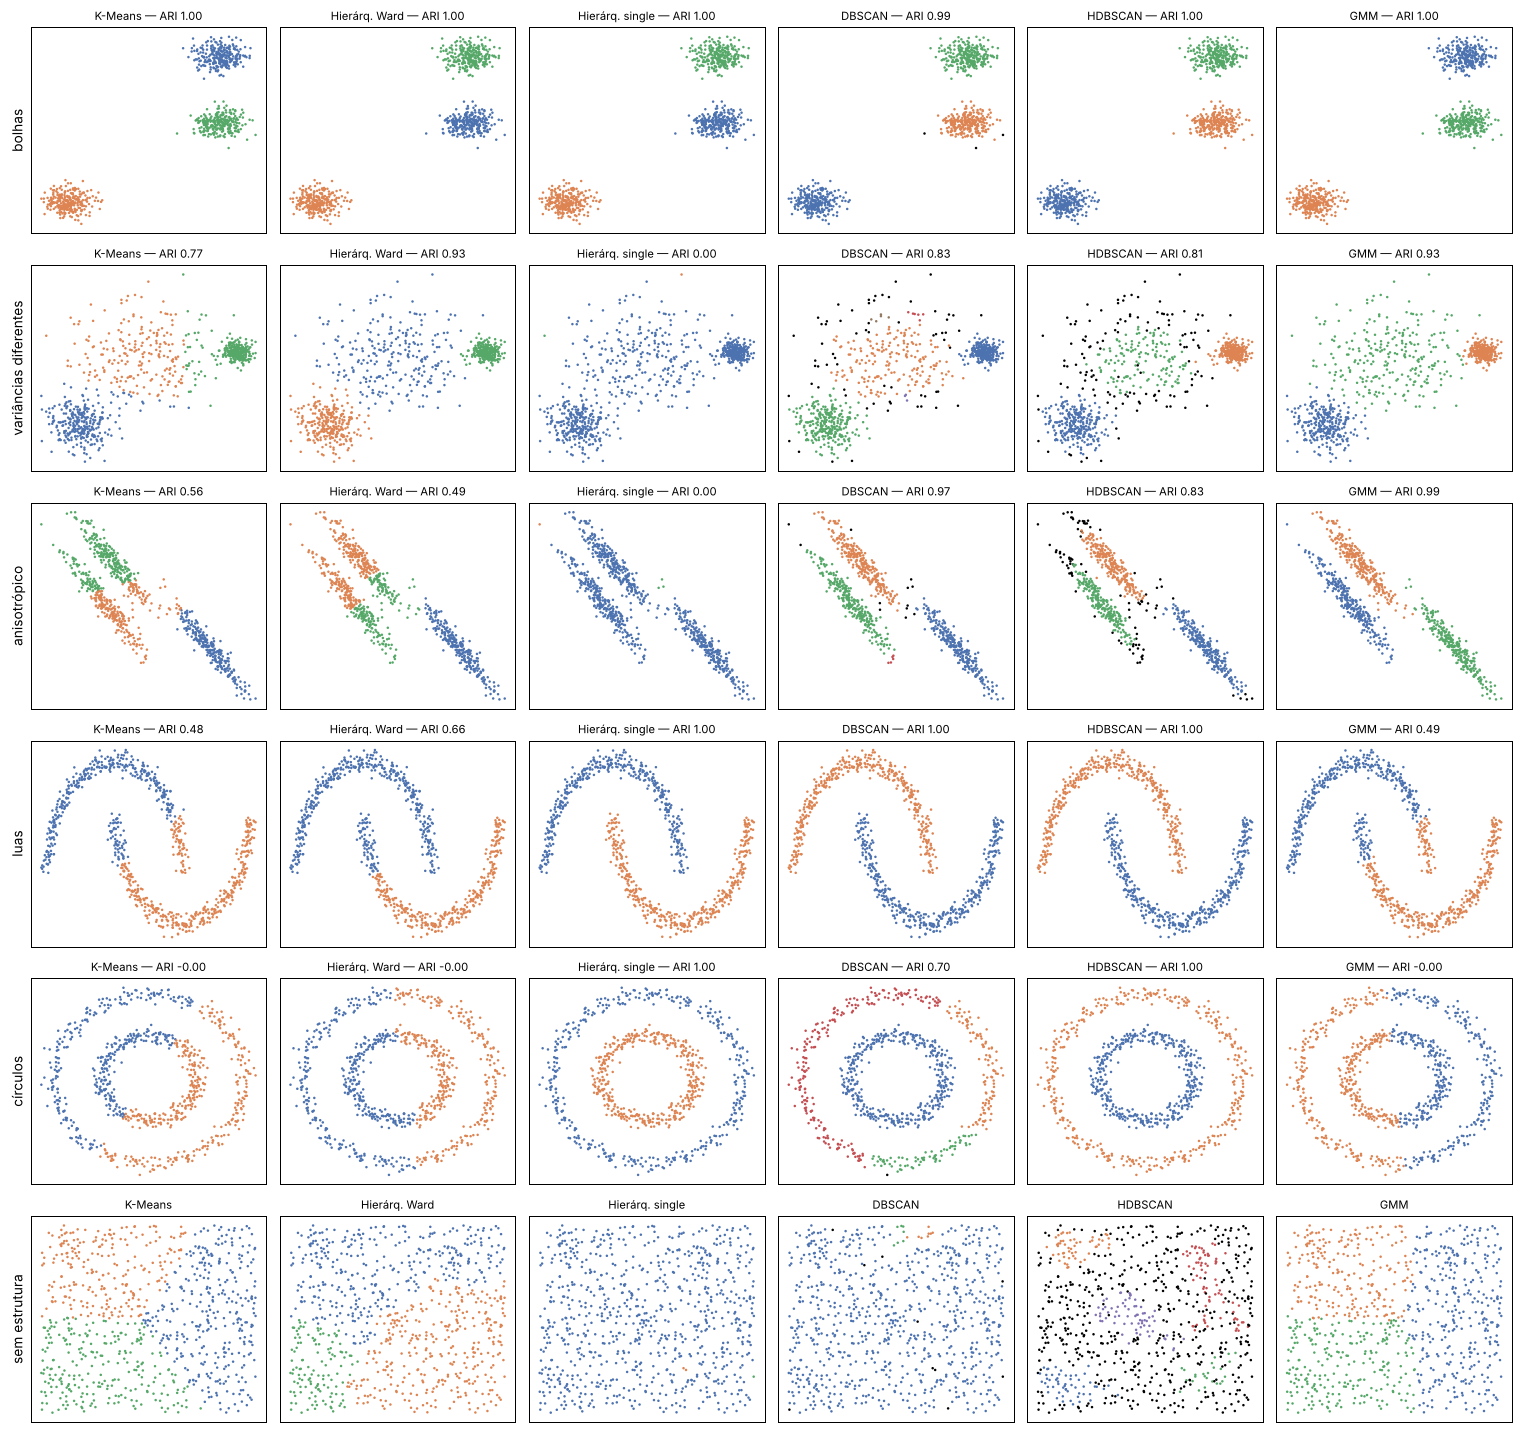

In [8]:
n = 800
conjuntos = {
    "bolhas": datasets.make_blobs(n_samples=n, random_state=8),
    "variâncias diferentes": datasets.make_blobs(n_samples=n, cluster_std=[1.0, 2.5, 0.5], random_state=170),
    "anisotrópico": (datasets.make_blobs(n_samples=n, random_state=170)[0] @ np.array([[0.6, -0.64], [-0.41, 0.85]]),
                     datasets.make_blobs(n_samples=n, random_state=170)[1]),
    "luas": datasets.make_moons(n_samples=n, noise=0.05, random_state=SEMENTE),
    "círculos": datasets.make_circles(n_samples=n, factor=0.5, noise=0.05, random_state=SEMENTE),
    "sem estrutura": (np.random.default_rng(SEMENTE).random((n, 2)), None),
}
k_por_conjunto = {"luas": 2, "círculos": 2}

def algoritmos(k):
    return {
        "K-Means": KMeans(k, n_init=10, random_state=SEMENTE),
        "Hierárq. Ward": AgglomerativeClustering(k, linkage="ward"),
        "Hierárq. single": AgglomerativeClustering(k, linkage="single"),
        "DBSCAN": DBSCAN(eps=0.18, min_samples=5),
        "HDBSCAN": HDBSCAN(min_cluster_size=20, copy=True),
        "GMM": GaussianMixture(k, covariance_type="full", random_state=SEMENTE),
    }

nomes_alg = list(algoritmos(2))
fig, axs = plt.subplots(len(conjuntos), len(nomes_alg), figsize=(17, 16))
resultados = []
for i, (nome_c, (Xc, yc)) in enumerate(conjuntos.items()):
    Xc = StandardScaler().fit_transform(Xc)
    k = k_por_conjunto.get(nome_c, 3)
    for j, (nome_a, alg) in enumerate(algoritmos(k).items()):
        rot = alg.fit_predict(Xc)
        nota = adjusted_rand_score(yc, rot) if yc is not None else np.nan
        resultados.append({"dados": nome_c, "algoritmo": nome_a, "ARI": nota,
                           "nº clusters": len(set(rot) - {-1}), "% ruído": 100 * np.mean(rot == -1)})
        dispersao_clusters(axs[i, j], Xc, rot, f"{nome_a}" + ("" if np.isnan(nota) else f" — ARI {nota:.2f}"), s=4)
        if j == 0:
            axs[i, j].set_ylabel(nome_c, fontsize=11)
plt.tight_layout()

In [9]:
res = pd.DataFrame(resultados)
display(res.pivot(index="dados", columns="algoritmo", values="ARI").round(2)[nomes_alg])
print("Conjunto SEM estrutura — quantos clusters cada algoritmo 'encontrou':")
res[res.dados == "sem estrutura"].set_index("algoritmo")[["nº clusters", "% ruído"]].round(1).T

algoritmo,K-Means,Hierárq. Ward,Hierárq. single,DBSCAN,HDBSCAN,GMM
dados,,,,,,
anisotrópico,0.56,0.49,0.0,0.97,0.83,0.99
bolhas,1.00,1.00,1.0,0.99,1.00,1.00
círculos,-0.00,-0.00,1.0,0.70,1.00,-0.00
luas,0.48,0.66,1.0,1.00,1.00,0.49
sem estrutura,NaN,NaN,NaN,NaN,NaN,NaN
variâncias diferentes,0.77,0.93,0.0,0.83,0.81,0.93


Conjunto SEM estrutura — quantos clusters cada algoritmo 'encontrou':


algoritmo,K-Means,Hierárq. Ward,Hierárq. single,DBSCAN,HDBSCAN,GMM
nº clusters,3.0,3.0,3.0,3.0,5.0,3.0
% ruído,0.0,0.0,0.0,1.2,65.5,0.0


**Leitura sugerida:**
- **K-Means / Ward / GMM** brilham em grupos convexos; falham em luas e círculos.
- No caso **anisotrópico**, entre os que recebem *k*, só o **GMM** (covariância completa) acerta;
  DBSCAN também acerta porque os grupos estão bem separados por regiões vazias.
- **Single linkage / DBSCAN / HDBSCAN** acertam formas não convexas, mas sofrem com densidades diferentes
  (o HDBSCAN sofre menos).
- No conjunto **sem estrutura**, os algoritmos que recebem *k* devolvem 3 "clusters" mesmo assim — o algoritmo
  **sempre** responde; cabe a você verificar se faz sentido. Atenção: a tabela diz que single e DBSCAN acharam
  "3 clusters", mas o gráfico mostra um grupo gigante e dois minúsculos — **olhe o tamanho dos grupos**, não só a contagem.
  O HDBSCAN marca a maior parte como ruído, o que é a resposta honesta para dados uniformes.

## 7. O efeito da padronização na clusterização

Mesmos dados de bolhas, mas multiplicamos a 2ª coluna por 100 (como mudar a unidade de metros para centímetros).

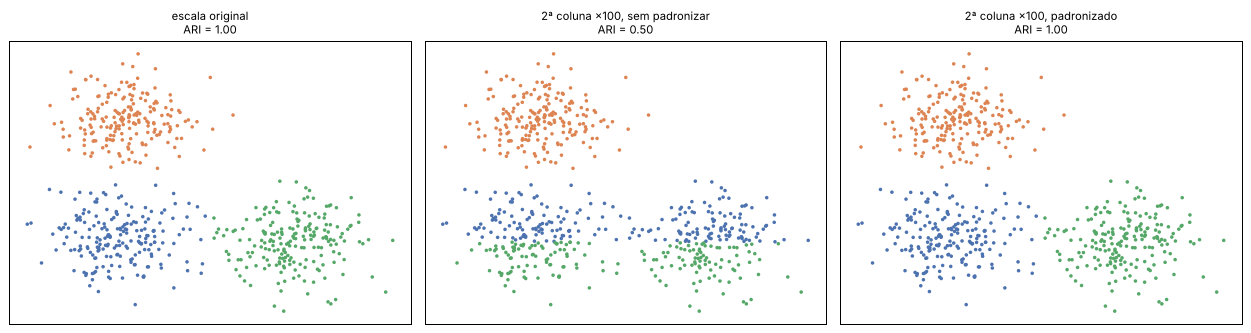

In [10]:
Xb, yb = datasets.make_blobs(n_samples=600, centers=[[0, 0], [5, 0], [0, 5]], random_state=0)
Xb_esc = Xb * np.array([1, 100])

fig, axs = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (tit, dados) in zip(axs, [("escala original", Xb), ("2ª coluna ×100, sem padronizar", Xb_esc),
                                  ("2ª coluna ×100, padronizado", StandardScaler().fit_transform(Xb_esc))]):
    rot = KMeans(3, n_init=10, random_state=0).fit_predict(dados)
    dispersao_clusters(ax, Xb, rot, f"{tit}\nARI = {adjusted_rand_score(yb, rot):.2f}")
plt.tight_layout()

Os pontos são plotados sempre na escala original para comparar. Uma simples troca de unidade destrói o
agrupamento — e a padronização recupera o resultado.

## 8. Exercícios

1. Na seção 1, troque a inicialização por `X[[0, 150, 300]]` ou por pontos aleatórios. Quantas iterações são necessárias?
2. Na seção 2, aumente `cluster_std` para 2.5. O cotovelo e a silhueta ainda indicam *k* = 4?
3. Na seção 6, ajuste `eps` do DBSCAN para acertar o conjunto "variâncias diferentes". É possível acertar todos ao mesmo tempo?
4. Calcule a silhueta dos resultados do DBSCAN nas luas e compare com a do K-Means. A métrica concorda com o ARI? (dica: [06_avaliacao.md](06_avaliacao.md))
5. Desafio: implemente o K-Means completo (com critério de parada) a partir de `passo_lloyd` e compare com o do scikit-learn.